In [42]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import convolve
import time


In [43]:
def dfe_equalizer(
    received,
    desired,
    num_ff_taps=5,
    num_fb_taps=3,
    mu=0.001
):
    """
    Adaptive Decision Feedback Equalizer.

    During training, the known transmitted symbols are
    used in the feedback section (teacher forcing).
    """

    ff_weights = np.zeros(num_ff_taps)
    fb_weights = np.zeros(num_fb_taps)

    # Start with a pass-through feed-forward filter
    ff_weights[num_ff_taps // 2] = 1.0

    output = np.zeros(len(desired))
    errors = np.zeros(len(desired))
    decisions = np.zeros(len(desired))

    for n in range(num_ff_taps, len(desired)):

        # -------------------------
        # Feed-forward section
        # -------------------------

        x = received[
            n - num_ff_taps + 1 : n + 1
        ]

        if len(x) != num_ff_taps:
            continue

        ff_output = np.dot(
            ff_weights,
            x
        )

        # -------------------------
        # Feedback section
        # -------------------------

        if n >= num_fb_taps:

            # During training, use the ACTUAL
            # previously transmitted symbols.
            previous_symbols = desired[
                n - num_fb_taps : n
            ]

            fb_output = np.dot(
                fb_weights,
                previous_symbols
            )

        else:

            previous_symbols = np.zeros(num_fb_taps)
            fb_output = 0.0

        # -------------------------
        # Combine FFE + feedback
        # -------------------------

        y = ff_output - fb_output

        output[n] = y

        # -------------------------
        # Training error
        # -------------------------

        error = desired[n] - y

        errors[n] = error

        # -------------------------
        # Make decision
        # -------------------------

        decisions[n] = pam4_detect(
            np.array([y])
        )[0]

        # -------------------------
        # Update FFE
        # -------------------------

        ff_weights += (
            mu * error * x
        )

        # -------------------------
        # Update feedback filter
        # -------------------------

        if n >= num_fb_taps:

            fb_weights -= (
                mu
                * error
                * previous_symbols
            )

    return (
        output,
        errors,
        decisions,
        ff_weights,
        fb_weights
    )

In [72]:
def bits_to_pam4(bits):
    bit_pairs = bits.reshape(-1, 2)

    symbols = np.array([
        pam4_mapping[tuple(pair)]
        for pair in bit_pairs
    ])

    return symbols

In [73]:
samples_per_symbol = 10

pam4_mapping = {
    (0, 0): -3,
    (0, 1): -1,
    (1, 1): 1,
    (1, 0): 3
}

pam4_to_bits = {
    -3: (0, 0),
    -1: (0, 1),
     1: (1, 1),
     3: (1, 0)
}

channel = np.array([0.1, 0.2, 0.5, 0.2, 0.1])

channel_test = np.array([
    0.15,
    0.30,
    0.40,
    0.30,
    0.15
])

channel_test = channel_test / np.sum(channel_test)

print("Test channel:", channel_test)

num_bits = 100_000
snr_db = 15

Test channel: [0.11538462 0.23076923 0.30769231 0.23076923 0.11538462]


In [46]:
def pam4_detect(samples):
    detected = np.zeros(len(samples), dtype=int)

    detected[samples < -2] = -3
    detected[(samples >= -2) & (samples < 0)] = -1
    detected[(samples >= 0) & (samples < 2)] = 1
    detected[samples >= 2] = 3

    return detected

In [47]:
def apply_channel_fse(
    symbols,
    channel,
    samples_per_symbol,
    snr_db,
    fse_samples_per_symbol=2
):
    """
    Generate received samples for a fractionally-spaced equalizer.
    """

    # Oversample transmitted PAM4 symbols
    tx_waveform = np.repeat(symbols, samples_per_symbol)

    # Apply channel
    rx_noiseless = convolve(
        tx_waveform,
        channel,
        mode="same"
    )

    # Calculate noise power
    signal_power = np.mean(rx_noiseless ** 2)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / snr_linear

    # Add AWGN
    noise = np.random.normal(
        0,
        np.sqrt(noise_power),
        len(rx_noiseless)
    )

    rx_signal = rx_noiseless + noise

    # Select evenly spaced samples
    spacing = samples_per_symbol // fse_samples_per_symbol

    sample_indices = np.arange(
        samples_per_symbol // 2,
        len(rx_signal),
        spacing
    )

    rx_samples = rx_signal[sample_indices]

    return rx_samples

In [48]:
# Generate training data
train_bits = np.random.randint(0, 2, 2000)
train_symbols = bits_to_pam4(train_bits)

# Generate received waveform
train_received_fse = apply_channel_fse(
    train_symbols,
    channel_test,
    samples_per_symbol,
    snr_db=14,
    fse_samples_per_symbol=2
)

# Take one sample per symbol for our first DFE
train_received = train_received_fse[::2]

print("Transmitted symbols:", len(train_symbols))
print("DFE input samples:", len(train_received))

Transmitted symbols: 1000
DFE input samples: 1000


In [49]:
dfe_output, dfe_errors, dfe_decisions, ff_weights, fb_weights = dfe_equalizer(
    train_received,
    train_symbols,
    num_ff_taps=5,
    num_fb_taps=3,
    mu=0.001
)

print("Feed-forward weights:")
print(ff_weights)

print("\nFeedback weights:")
print(fb_weights)

Feed-forward weights:
[ 0.01715463  0.00913616  0.44512965 -0.00785939  0.9679362 ]

Feedback weights:
[-0.01604673  0.45802061 -0.00245525]


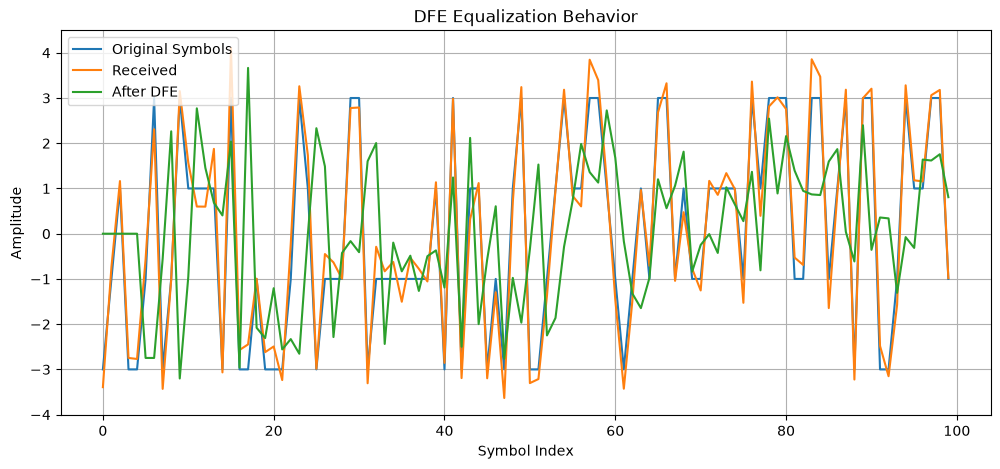

In [50]:
plt.figure(figsize=(12, 5))

plt.plot(
    train_symbols[:100],
    label="Original Symbols"
)

plt.plot(
    train_received[:100],
    label="Received"
)

plt.plot(
    dfe_output[:100],
    label="After DFE"
)

plt.xlabel("Symbol Index")
plt.ylabel("Amplitude")
plt.title("DFE Equalization Behavior")
plt.legend()
plt.grid(True)

plt.show()

In [51]:
# Calculate DFE symbol error rate

dfe_detected = pam4_detect(dfe_output)

valid_start = 5
valid_end = len(train_symbols) - 5

symbol_errors = np.sum(
    dfe_detected[valid_start:valid_end]
    != train_symbols[valid_start:valid_end]
)

symbol_count = valid_end - valid_start

ser = symbol_errors / symbol_count

print("========== DFE VALIDATION ==========")
print(f"Symbol errors: {symbol_errors}")
print(f"Symbol error rate: {ser:.6f}")

========== DFE VALIDATION ==========
Symbol errors: 171
Symbol error rate: 0.172727


In [52]:
# Look at the first 30 DFE decisions

print("Index | Transmitted | Received | DFE Output | DFE Decision")
print("-" * 65)

for i in range(5, 35):
    print(
        f"{i:5d} | "
        f"{train_symbols[i]:11.0f} | "
        f"{train_received[i]:8.3f} | "
        f"{dfe_output[i]:10.3f} | "
        f"{dfe_decisions[i]:12.0f}"
    )

Index | Transmitted | Received | DFE Output | DFE Decision
-----------------------------------------------------------------
    5 |          -1 |   -0.565 |     -2.747 |           -3
    6 |           3 |    2.308 |     -2.747 |           -3
    7 |          -3 |   -3.431 |     -0.554 |           -1
    8 |          -1 |   -1.014 |      2.263 |            3
    9 |           3 |    3.152 |     -3.201 |           -3
   10 |           1 |    1.570 |     -0.953 |           -1
   11 |           1 |    0.601 |      2.771 |            3
   12 |           1 |    0.598 |      1.454 |            1
   13 |           1 |    1.875 |      0.684 |            1
   14 |          -3 |   -3.066 |      0.404 |            1
   15 |           3 |    4.105 |      2.038 |            3
   16 |          -3 |   -2.571 |     -2.961 |           -3
   17 |          -3 |   -2.447 |      3.665 |            3
   18 |          -1 |   -0.995 |     -2.080 |           -3
   19 |          -3 |   -2.618 |     -2.308 |    

In [53]:
def fse_dfe_equalizer(
    received,
    desired,
    samples_per_symbol=2,
    num_ff_taps=5,
    num_fb_taps=3,
    mu=0.001
):
    """
    Fractionally-Spaced Decision Feedback Equalizer.

    The feed-forward section uses the same sample alignment
    as the FSE-LMS equalizer.

    During training, the known transmitted symbols are
    used in the feedback section.
    """

    ff_weights = np.zeros(num_ff_taps)
    fb_weights = np.zeros(num_fb_taps)

    # Center tap initialization
    center = num_ff_taps // 2
    ff_weights[center] = 1.0

    output = np.zeros(len(desired))
    errors = np.zeros(len(desired))
    decisions = np.zeros(len(desired))

    num_symbols = min(
        len(desired),
        len(received) // samples_per_symbol
    )

    for n in range(
        max(center, num_fb_taps),
        num_symbols - center
    ):

        # --------------------------------
        # Feed-forward input
        # --------------------------------

        start = (
            n * samples_per_symbol
            - center
        )

        x = received[
            start : start + num_ff_taps
        ]

        if len(x) != num_ff_taps:
            continue

        # --------------------------------
        # Feed-forward output
        # --------------------------------

        ff_output = np.dot(
            ff_weights,
            x
        )

        # --------------------------------
        # Feedback section
        # --------------------------------

        previous_symbols = desired[
            n - num_fb_taps : n
        ]

        fb_output = np.dot(
            fb_weights,
            previous_symbols
        )

        # --------------------------------
        # Equalizer output
        # --------------------------------

        y = ff_output - fb_output

        output[n] = y

        # --------------------------------
        # Training error
        # --------------------------------

        error = desired[n] - y

        errors[n] = error

        # --------------------------------
        # PAM4 decision
        # --------------------------------

        decisions[n] = pam4_detect(
            np.array([y])
        )[0]

        # --------------------------------
        # Update feed-forward filter
        # --------------------------------

        ff_weights += (
            mu * error * x
        )

        # --------------------------------
        # Update feedback filter
        # --------------------------------

        fb_weights -= (
            mu
            * error
            * previous_symbols
        )

    return (
        output,
        errors,
        decisions,
        ff_weights,
        fb_weights
    )

In [54]:
fse_dfe_output, fse_dfe_errors, fse_dfe_decisions, fse_dfe_ff, fse_dfe_fb = fse_dfe_equalizer(
    train_received_fse,
    train_symbols,
    samples_per_symbol=2,
    num_ff_taps=5,
    num_fb_taps=3,
    mu=0.001
)

print("FSE-DFE feed-forward weights:")
print(fse_dfe_ff)

print("\nFSE-DFE feedback weights:")
print(fse_dfe_fb)

FSE-DFE feed-forward weights:
[-0.00846515  0.05748665  0.93393855  0.02286439 -0.01437324]

FSE-DFE feedback weights:
[-0.01028904  0.0011595   0.00650053]


In [55]:
# Validate FSE-DFE symbol decisions

fse_dfe_detected = pam4_detect(
    fse_dfe_output
)

valid_start = 5
valid_end = len(train_symbols) - 5

symbol_errors = np.sum(
    fse_dfe_detected[valid_start:valid_end]
    != train_symbols[valid_start:valid_end]
)

symbol_count = valid_end - valid_start

fse_dfe_ser = symbol_errors / symbol_count

print("========== FSE-DFE VALIDATION ==========")
print(f"Symbol errors: {symbol_errors}")
print(f"Symbol error rate: {fse_dfe_ser:.6f}")

========== FSE-DFE VALIDATION ==========
Symbol errors: 16
Symbol error rate: 0.016162


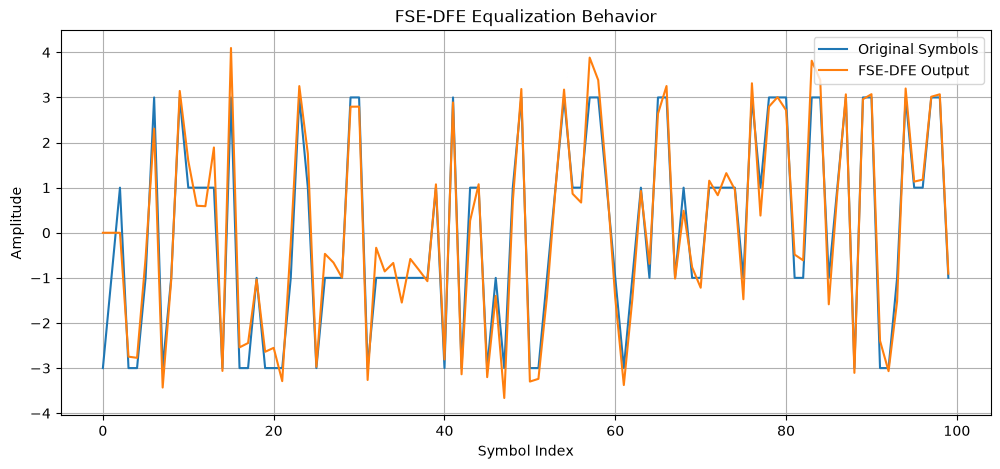

In [56]:
plt.figure(figsize=(12, 5))

plt.plot(
    train_symbols[:100],
    label="Original Symbols"
)

plt.plot(
    fse_dfe_output[:100],
    label="FSE-DFE Output"
)

plt.xlabel("Symbol Index")
plt.ylabel("Amplitude")
plt.title("FSE-DFE Equalization Behavior")
plt.legend()
plt.grid(True)

plt.show()

In [58]:
def pam4_to_bits(symbols):
    """
    Convert PAM4 symbols back into bits.

    Mapping:
        -3 -> 00
        -1 -> 01
        +1 -> 10
        +3 -> 11
    """

    bit_map = {
        -3: [0, 0],
        -1: [0, 1],
         1: [1, 0],
         3: [1, 1]
    }

    bits = []

    for symbol in symbols:
        bits.extend(bit_map[int(symbol)])

    return np.array(bits)

In [62]:
# DFE configuration
num_ff_taps = 5
num_fb_taps = 3

center = num_ff_taps // 2

# The FSE-DFE only processes symbols in this range:
# from max(center, num_fb_taps)
# to num_symbols - center
num_symbols = min(
    len(train_symbols),
    len(train_received_fse) // 2
)

start_symbol = max(center, num_fb_taps)
end_symbol = num_symbols - center

# Get ONLY symbols that were actually processed
valid_decisions = fse_dfe_decisions[start_symbol:end_symbol]
valid_transmitted_symbols = train_symbols[start_symbol:end_symbol]

# Make sure there are no invalid decisions
print("Valid symbols:", len(valid_decisions))
print("Unique DFE decisions:", np.unique(valid_decisions))

# Convert symbols to bits
dfe_bits = pam4_to_bits(valid_decisions)
original_bits = pam4_to_bits(valid_transmitted_symbols)

# Calculate BER
bit_errors = np.sum(dfe_bits != original_bits)
total_bits = len(original_bits)

dfe_ber = bit_errors / total_bits

print("\n========== FSE-DFE BER ==========")
print(f"SNR: 14 dB")
print(f"Bit errors: {bit_errors}")
print(f"Total bits: {total_bits}")
print(f"BER: {dfe_ber:.6f}")

Valid symbols: 994
Unique DFE decisions: [-3. -1.  1.  3.]

========== FSE-DFE BER ==========
SNR: 14 dB
Bit errors: 20
Total bits: 1988
BER: 0.010060


In [63]:
snr_values = np.arange(0, 21, 2)

fse_dfe_ber_results = []

for snr_db in snr_values:

    # Generate fresh random training data
    bits = np.random.randint(0, 2, 20000)
    symbols = bits_to_pam4(bits)

    # Pass through the same channel
    received = apply_channel_fse(
        symbols,
        channel_test,
        samples_per_symbol,
        snr_db=snr_db,
        fse_samples_per_symbol=2
    )

    # Run FSE-DFE
    dfe_output, dfe_errors, dfe_decisions, _, _ = fse_dfe_equalizer(
        received,
        symbols,
        samples_per_symbol=2,
        num_ff_taps=5,
        num_fb_taps=3,
        mu=0.001
    )

    # Determine valid symbol range
    center = 5 // 2
    num_symbols = min(
        len(symbols),
        len(received) // 2
    )

    start_symbol = max(center, 3)
    end_symbol = num_symbols - center

    valid_decisions = dfe_decisions[
        start_symbol:end_symbol
    ]

    valid_symbols = symbols[
        start_symbol:end_symbol
    ]

    # Convert symbols to bits
    predicted_bits = pam4_to_bits(valid_decisions)
    true_bits = pam4_to_bits(valid_symbols)

    # Calculate BER
    bit_errors = np.sum(
        predicted_bits != true_bits
    )

    total_bits = len(true_bits)

    ber = bit_errors / total_bits

    fse_dfe_ber_results.append(ber)

    print(
        f"SNR = {snr_db:2d} dB | "
        f"FSE-DFE BER = {ber:.6f}"
    )

SNR =  0 dB | FSE-DFE BER = 0.301331
SNR =  2 dB | FSE-DFE BER = 0.242095
SNR =  4 dB | FSE-DFE BER = 0.190464
SNR =  6 dB | FSE-DFE BER = 0.133330
SNR =  8 dB | FSE-DFE BER = 0.077396
SNR = 10 dB | FSE-DFE BER = 0.039224
SNR = 12 dB | FSE-DFE BER = 0.014509
SNR = 14 dB | FSE-DFE BER = 0.002852
SNR = 16 dB | FSE-DFE BER = 0.000350
SNR = 18 dB | FSE-DFE BER = 0.000000
SNR = 20 dB | FSE-DFE BER = 0.000000


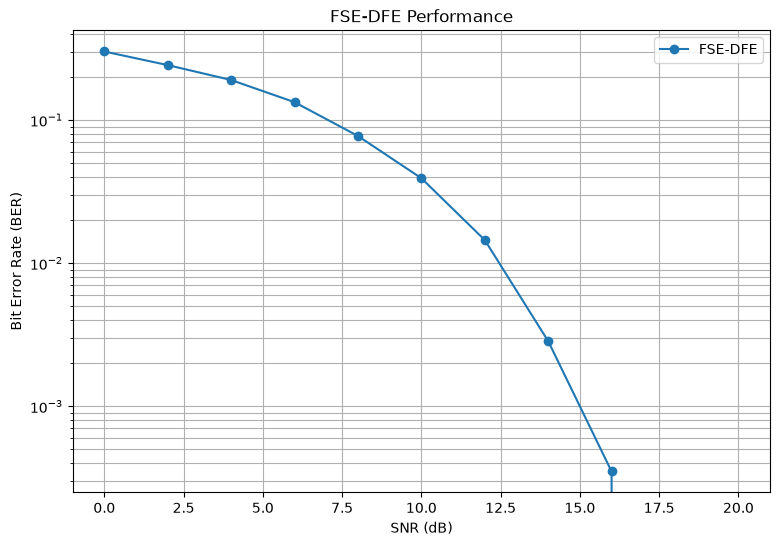

In [64]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    snr_values,
    fse_dfe_ber_results,
    marker="o",
    label="FSE-DFE"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("FSE-DFE Performance")
plt.grid(True, which="both")
plt.legend()

plt.show()

In [65]:
import time

# Generate training data
timing_bits = np.random.randint(0, 2, 20000)
timing_symbols = bits_to_pam4(timing_bits)

timing_received = apply_channel_fse(
    timing_symbols,
    channel_test,
    samples_per_symbol,
    snr_db=14,
    fse_samples_per_symbol=2
)

# Measure training time
start_time = time.perf_counter()

fse_dfe_output, fse_dfe_errors, fse_dfe_decisions, fse_dfe_ff, fse_dfe_fb = fse_dfe_equalizer(
    timing_received,
    timing_symbols,
    samples_per_symbol=2,
    num_ff_taps=5,
    num_fb_taps=3,
    mu=0.001
)

end_time = time.perf_counter()

dfe_training_time = end_time - start_time

print(f"FSE-DFE training time: {dfe_training_time:.6f} seconds")

FSE-DFE training time: 0.108364 seconds


In [66]:
def fse_dfe_inference(
    received,
    ff_weights,
    fb_weights,
    samples_per_symbol=2,
    num_ff_taps=5,
    num_fb_taps=3
):
    """
    Run a trained FSE-DFE without updating its weights.
    """

    output = np.zeros(
        len(received) // samples_per_symbol
    )

    decisions = np.zeros(
        len(output)
    )

    center = num_ff_taps // 2

    for n in range(
        max(center, num_fb_taps),
        len(output) - center
    ):

        start = (
            n * samples_per_symbol
            - center
        )

        x = received[
            start : start + num_ff_taps
        ]

        if len(x) != num_ff_taps:
            continue

        # Feed-forward
        ff_output = np.dot(
            ff_weights,
            x
        )

        # Feedback uses previous DECISIONS
        previous_decisions = decisions[
            n - num_fb_taps : n
        ]

        fb_output = np.dot(
            fb_weights,
            previous_decisions
        )

        # Equalized output
        y = ff_output - fb_output

        output[n] = y

        # Make decision
        decisions[n] = pam4_detect(
            np.array([y])
        )[0]

    return output, decisions

In [67]:
# Measure inference latency

start_time = time.perf_counter()

inference_output, inference_decisions = fse_dfe_inference(
    timing_received,
    fse_dfe_ff,
    fse_dfe_fb,
    samples_per_symbol=2,
    num_ff_taps=5,
    num_fb_taps=3
)

end_time = time.perf_counter()

dfe_inference_time = end_time - start_time

print(f"FSE-DFE inference time: {dfe_inference_time:.6f} seconds")

FSE-DFE inference time: 0.073483 seconds


In [68]:
num_dfe_parameters = (
    len(fse_dfe_ff) +
    len(fse_dfe_fb)
)

print(f"FSE-DFE feed-forward taps: {len(fse_dfe_ff)}")
print(f"FSE-DFE feedback taps: {len(fse_dfe_fb)}")
print(f"Total DFE coefficients: {num_dfe_parameters}")

FSE-DFE feed-forward taps: 5
FSE-DFE feedback taps: 3
Total DFE coefficients: 8


In [69]:
dfe_results = {
    "Equalizer": "FSE-DFE",
    "BER_14dB": 0.002852,
    "Training_Time_s": 0.108364,
    "Inference_Time_s": 0.073483,
    "Num_Parameters": 8
}

print("========== FSE-DFE BENCHMARK ==========")

for key, value in dfe_results.items():
    print(f"{key}: {value}")

========== FSE-DFE BENCHMARK ==========
Equalizer: FSE-DFE
BER_14dB: 0.002852
Training_Time_s: 0.108364
Inference_Time_s: 0.073483
Num_Parameters: 8


In [71]:
import pandas as pd
dfe_ber_table = pd.DataFrame({
    "SNR_dB": snr_values,
    "FSE_DFE_BER": fse_dfe_ber_results
})

print(dfe_ber_table)

    SNR_dB  FSE_DFE_BER
0        0     0.301331
1        2     0.242095
2        4     0.190464
3        6     0.133330
4        8     0.077396
5       10     0.039224
6       12     0.014509
7       14     0.002852
8       16     0.000350
9       18     0.000000
10      20     0.000000


In [74]:
# ============================================
# STANDARDIZED INFERENCE BENCHMARK
# ============================================

BENCHMARK_SYMBOLS = 10_000
NUM_RUNS = 20

print("Benchmark symbols:", BENCHMARK_SYMBOLS)
print("Timing runs:", NUM_RUNS)

Benchmark symbols: 10000
Timing runs: 20


In [77]:
# ============================================
# CREATE STANDARDIZED BENCHMARK INPUT
# ============================================

benchmark_bits = np.random.randint(
    0, 2, BENCHMARK_SYMBOLS * 2
)

benchmark_symbols = bits_to_pam4(benchmark_bits)

benchmark_received = apply_channel_fse(
    benchmark_symbols,
    channel_test,
    samples_per_symbol=2,
    snr_db=14
)

print("Benchmark symbols:", len(benchmark_symbols))
print("Benchmark received samples:", len(benchmark_received))

Benchmark symbols: 10000
Benchmark received samples: 19999


In [78]:
# ============================================
# FSE-DFE INFERENCE BENCHMARK
# ============================================

# Warm-up
_ = fse_dfe_equalizer(
    benchmark_received,
    benchmark_symbols,
    samples_per_symbol=2,
    num_ff_taps=5,
    num_fb_taps=3
)

times = []

for _ in range(NUM_RUNS):

    start = time.perf_counter()

    _ = fse_dfe_equalizer(
        benchmark_received,
        benchmark_symbols,
        samples_per_symbol=2,
        num_ff_taps=5,
        num_fb_taps=3
    )

    end = time.perf_counter()

    times.append(end - start)

fse_dfe_benchmark_time = np.mean(times)

print(
    f"FSE-DFE inference time for "
    f"{BENCHMARK_SYMBOLS:,} symbols: "
    f"{fse_dfe_benchmark_time:.6f} s"
)

print(
    f"FSE-DFE time per symbol: "
    f"{fse_dfe_benchmark_time / BENCHMARK_SYMBOLS:.9f} s"
)

FSE-DFE inference time for 10,000 symbols: 0.092978 s
FSE-DFE time per symbol: 0.000009298 s
